In [ ]:
import pandas as ?
import numpy as ?
import matplotlib.pyplot as ?
import seaborn as ?
from sklearn.svm import ?
from sklearn.model_selection import train_test_?, cross_?_?
from sklearn.preprocessing import MinMax?, Standard?
from sklearn.metrics import accuracy_?, ConfusionMatrix?, classification_?
from sklearn.pipeline import Pipe?
from sklearn.model_selection import Grid?

In [ ]:
#load dataset
df=pd.read_csv('https://raw.githubusercontent.com/arielb30/datasets/main/penguins.csv')
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female
...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male


In [ ]:
df.is?().?() #check and sum nulls

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [ ]:
df.drop?(axis=?, inplace=?) #drop nulls
?.?()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 333 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    object 
 1   island             333 non-null    object 
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 20.8+ KB


In [ ]:
#Chose attributes
X=?.?([?,?,?],axis=?).?_?() #drop object variables
?.?

(333, 4)

In [ ]:
y = ?[?].?_?() #target is sex
y.shape

(333,)

In [ ]:
#train test split
X_?,X_?,y_?,y_?=train_?_?(?,?,test_?=0.20,\
                                      shuffle=?,random_?=42)
print("train: ", X_?.shape, y_?.shape)
print("test:  " , X_?.shape, y_?.shape)

train:  (266, 4) (266,)
test:   (67, 4) (67,)


In [ ]:
pipe = Pipe?([
        ('scale', Standard?()),
        ('svc', ?())
        ])

In [ ]:
#Note format for dictionary keys: pipeName__parameterName
param_? = {
    '?__?': [?, ?, ?, ?],
    '?__?' :[?,?,?]
}
param_grid

{'svc__kernel': ['linear', 'poly', 'rbf', 'sigmoid'], 'svc__C': [1, 10, 100]}

In [ ]:
svm_clf = Grid?(?, param_grid=?_?, cv=?, verbose=1)
?_?.?(?_?, ?_?)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scale', StandardScaler()),
                                       ('svc', SVC())]),
             param_grid={'svc__C': [1, 10, 100],
                         'svc__kernel': ['linear', 'poly', 'rbf', 'sigmoid']},
             verbose=1)

In [ ]:
cv_results = pd.Data?(?_?.?_?_)
?_?[[?,?,?,?]].sort_?(?)

,param_svc__kernel,param_svc__C,mean_test_score,rank_test_score
4,linear,10,0.898393,1
9,poly,100,0.898323,2
6,rbf,10,0.894759,3
8,linear,100,0.894689,4
2,rbf,1,0.890985,5
0,linear,1,0.887142,6
5,poly,10,0.887142,6
10,rbf,100,0.872048,8
1,poly,1,0.868274,9
3,sigmoid,1,0.766876,10


In [ ]:
?_?.best_?_

{'svc__C': 10, 'svc__kernel': 'linear'}

In [ ]:
y_pred = ?_?.?(?_?) #predict on Test
?_?.?

(67,)

In [ ]:
#accuracy on test samples
accuracy_?(y_true=?_?, y_pred = ?_?)

0.8507462686567164

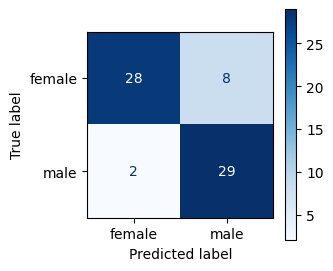

In [ ]:
#confusion matrix on test data
fig, ax = plt.subplots(figsize=(3, 3))
Confusion?.from_?(y_true=?_?,y_pred=?_?,\
                                values_format="d",cmap="Blues",ax=?);

In [ ]:
#classification report on test data
print(classification_?(y_true=?_?, y_pred=?_?))

              precision    recall  f1-score   support

      female       0.93      0.78      0.85        36
        male       0.78      0.94      0.85        31

    accuracy                           0.85        67
   macro avg       0.86      0.86      0.85        67
weighted avg       0.86      0.85      0.85        67

